goal is to find the best model settings for breast cancer dataset

In [2]:

# Task 9: Hyperparameter Tuning Using GridSearchCV

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt




*load the dataset using breast cancer dataset.
*store the input features in X and the target labels in y.
*use random_state=42 to make the split reproducible.
*parameter stratify=y helps maintain class proportions


In [3]:
# 1. Load and split the dataset
data = load_breast_cancer()
X = data.data
y = data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

create a pipeline containing two steps: StandardScaler and SVC.

*StandardScaler standardizes the input features so that they have comparable scales.
*SVC creates the Support Vector Machine classifier.


In [4]:
# 2. Create a pipeline with scaling and SVM
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svc", SVC())
])

*C controls the penalty for classification errors.
*gamma controls how far the influence of individual training samples extends.
*kernel="rbf" uses a nonlinear kernel that can identify more complex patterns.

In [5]:
# 3. Define hyperparameters to test
param_grid = {
    "svc__C": [0.1, 1, 10, 100],
    "svc__gamma": [0.001, 0.01, 0.1, 1],
    "svc__kernel": ["rbf"]
}


*use GridSearchCV to find the best combination of hyperparameters
*use accuracy as the evaluation metric, and GridSearchCV selects the combination with the highest average validation accuracy

In [6]:
# 4. Apply five-fold cross-validation
grid_search = GridSearchCV(
    pipeline,
    param_grid,
    cv=5,
    scoring="accuracy"
)

grid_search.fit(X_train, y_train)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('scaler', StandardScaler()),
                                       ('svc', SVC())]),
             param_grid={'svc__C': [0.1, 1, 10, 100],
                         'svc__gamma': [0.001, 0.01, 0.1, 1],
                         'svc__kernel': ['rbf']},
             scoring='accuracy')

In [7]:
# 5. Display best parameters and cross-validation score
print("Best Parameters:", grid_search.best_params_)
print("Best Cross-Validation Accuracy:",
      round(grid_search.best_score_, 4))

Best Parameters: {'svc__C': 10, 'svc__gamma': 0.01, 'svc__kernel': 'rbf'}
Best Cross-Validation Accuracy: 0.9802


*retrieve the optimized model and use it to predict the labels of the test data
*calculate its test accuracy by comparing the predicted labels with the actual labels

In [8]:

# 6. Evaluate the optimized model on the test set
best_model = grid_search.best_estimator_
optimized_predictions = best_model.predict(X_test)
optimized_accuracy = accuracy_score(y_test, optimized_predictions)



In [9]:
# Train a default SVM using the same pipeline and training data
default_model = Pipeline([
    ("scaler", StandardScaler()),
    ("svc", SVC())
])

default_model.fit(X_train, y_train)
default_predictions = default_model.predict(X_test)
default_accuracy = accuracy_score(y_test, default_predictions)

*output compares the test accuracy of the default SVM and the optimized SVM.

In [10]:
# Compare test accuracy
print("\nTest Accuracy Comparison:")
print("Default SVM:", round(default_accuracy, 4))
print("Optimized SVM:", round(optimized_accuracy, 4))

models = ["Default SVM", "Optimized SVM"]
accuracies = [default_accuracy, optimized_accuracy]



Test Accuracy Comparison:
Default SVM: 0.9825
Optimized SVM: 0.9825


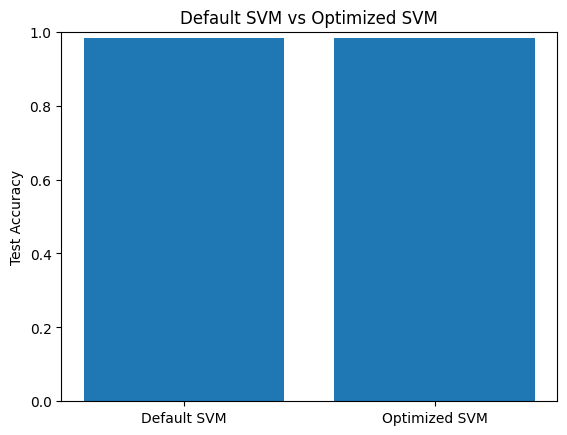

In [11]:
#figure
plt.bar(models, accuracies)
plt.ylabel("Test Accuracy")
plt.title("Default SVM vs Optimized SVM")
plt.ylim(0, 1)
plt.show()